In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load the Excel dataset
df = pd.read_excel("Online Retail.xlsx")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

print("\nDescriptive statistics:")
display(df.describe().round(2))

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     1350

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.00,541909,541909.00,406829.00
mean,9.55,2011-07-04 13:34:57.156386,4.61,15287.69
min,-80995.00,2010-12-01 08:26:00,-11062.06,12346.00
25%,1.00,2011-03-28 11:34:00,1.25,13953.00
50%,3.00,2011-07-19 17:17:00,2.08,15152.00
75%,10.00,2011-10-19 11:27:00,4.13,16791.00
max,80995.00,2011-12-09 12:50:00,38970.00,18287.00
std,218.08,NaN,96.76,1713.60


In [5]:
df = df.copy()

# Standardize column names
df.columns = df.columns.str.strip()

# Convert data types
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)
df["Quantity"] = pd.to_numeric(
    df["Quantity"], errors="coerce"
)
df["UnitPrice"] = pd.to_numeric(
    df["UnitPrice"], errors="coerce"
)
df["CustomerID"] = pd.to_numeric(
    df["CustomerID"], errors="coerce"
)

# Remove duplicate rows
df = df.drop_duplicates()

# Remove records missing required fields
df = df.dropna(
    subset=[
        "CustomerID", "InvoiceNo",
        "InvoiceDate", "Quantity", "UnitPrice"
    ]
)

df["CustomerID"] = df["CustomerID"].astype("int64")

# Exclude cancelled invoices, which commonly begin with C
df = df[
    ~df["InvoiceNo"].astype(str).str.upper().str.startswith("C")
].copy()

# Keep valid positive purchase quantities and prices
df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

# Calculate transaction-line revenue
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

print("Cleaned dataset shape:", df.shape)
print("Unique customers:", df["CustomerID"].nunique())
print("Unique invoices:", df["InvoiceNo"].nunique())
print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

display(df.head())

Cleaned dataset shape: (392692, 9)
Unique customers: 4338
Unique invoices: 18532
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [6]:
# Set the reference date to one day after the last transaction date
reference_date = (
    df["InvoiceDate"].max().normalize()
    + pd.Timedelta(days=1)
)

rfm = df.groupby("CustomerID").agg(
    Last_Purchase=("InvoiceDate", "max"),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum"),
    Total_Units=("Quantity", "sum")
)

# Days since the latest purchase
rfm["Recency"] = (
    reference_date - rfm["Last_Purchase"].dt.normalize()
).dt.days

# Average spending per distinct invoice
rfm["Average_Purchase_Value"] = (
    rfm["Monetary"] / rfm["Frequency"]
)

# Historical revenue as a proxy for observed customer value
rfm["Historical_Customer_Value"] = rfm["Monetary"]

rfm = rfm.reset_index()

display(rfm.head())
print("Number of customers:", len(rfm))

,CustomerID,Last_Purchase,Frequency,Monetary,Total_Units,Recency,Average_Purchase_Value,Historical_Customer_Value
0,12346,2011-01-18 10:01:00,1,77183.60,74215,326,77183.600000,77183.60
1,12347,2011-12-07 15:52:00,7,4310.00,2458,3,615.714286,4310.00
2,12348,2011-09-25 13:13:00,4,1797.24,2341,76,449.310000,1797.24
3,12349,2011-11-21 09:51:00,1,1757.55,631,19,1757.550000,1757.55
4,12350,2011-02-02 16:01:00,1,334.40,197,311,334.400000,334.40


Number of customers: 4338


In [7]:
customer_stats = rfm[
    [
        "Recency",
        "Frequency",
        "Monetary",
        "Average_Purchase_Value",
        "Historical_Customer_Value"
    ]
].agg(["mean", "median", "std", "min", "max"]).T

customer_stats.columns = [
    "Mean", "Median", "Standard Deviation", "Minimum", "Maximum"
]

display(customer_stats.round(2))

print("Average purchase value:",
      round(rfm["Average_Purchase_Value"].mean(), 2))

print("Average purchase frequency:",
      round(rfm["Frequency"].mean(), 2), "invoices per customer")

print("Average historical customer value:",
      round(rfm["Historical_Customer_Value"].mean(), 2))

,Mean,Median,Standard Deviation,Minimum,Maximum
Recency,93.06,51.00,100.01,1.00,374.00
Frequency,4.27,2.00,7.70,1.00,209.00
Monetary,2048.69,668.57,8985.23,3.75,280206.02
Average_Purchase_Value,417.65,291.94,1796.51,3.45,84236.25
Historical_Customer_Value,2048.69,668.57,8985.23,3.75,280206.02


Average purchase value: 417.65
Average purchase frequency: 4.27 invoices per customer
Average historical customer value: 2048.69


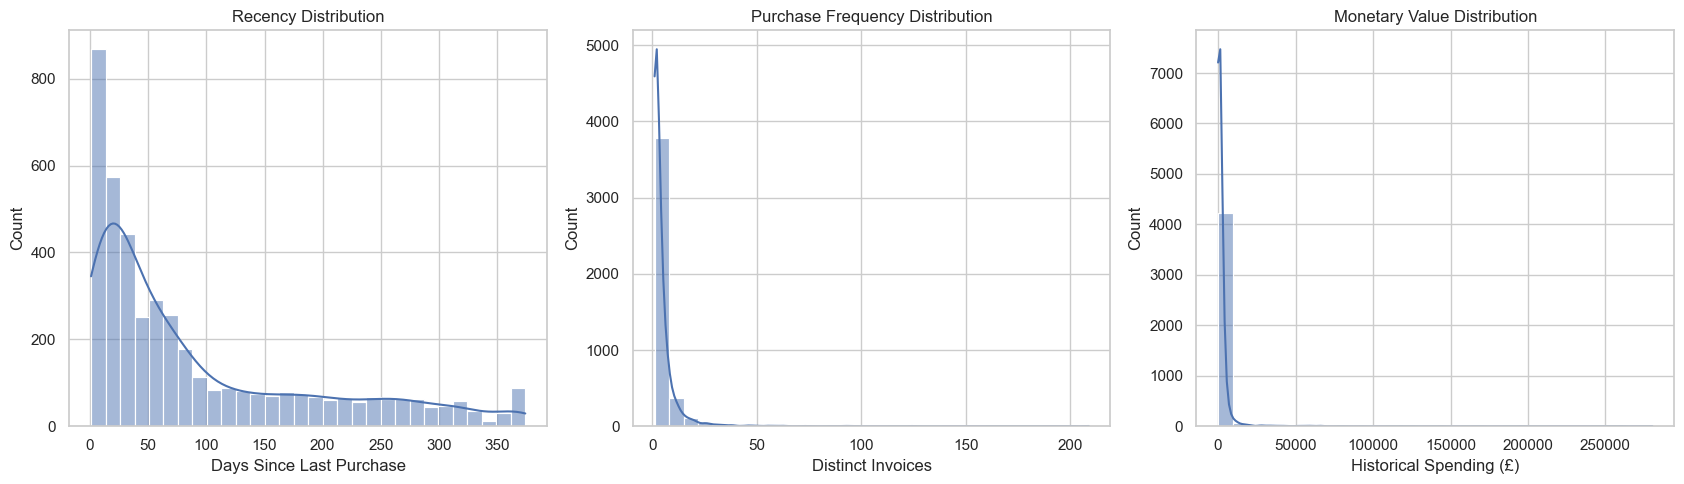

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.histplot(rfm["Recency"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Recency Distribution")
axes[0].set_xlabel("Days Since Last Purchase")

sns.histplot(rfm["Frequency"], bins=30, kde=True, ax=axes[1])
axes[1].set_title("Purchase Frequency Distribution")
axes[1].set_xlabel("Distinct Invoices")

sns.histplot(rfm["Monetary"], bins=30, kde=True, ax=axes[2])
axes[2].set_title("Monetary Value Distribution")
axes[2].set_xlabel("Historical Spending (£)")

plt.tight_layout()
plt.show()

In [9]:
features = ["Recency", "Frequency", "Monetary"]

X = rfm[features].copy()

# Reduce the influence of extreme right-skew
X_log = np.log1p(X)

# Standardize all selected features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("Feature matrix shape:", X_scaled.shape)

print("Feature means after scaling:",
      np.round(X_scaled.mean(axis=0), 3))

print("Feature standard deviations after scaling:",
      np.round(X_scaled.std(axis=0), 3))

Feature matrix shape: (4338, 3)
Feature means after scaling: [ 0. -0. -0.]
Feature standard deviations after scaling: [1. 1. 1.]


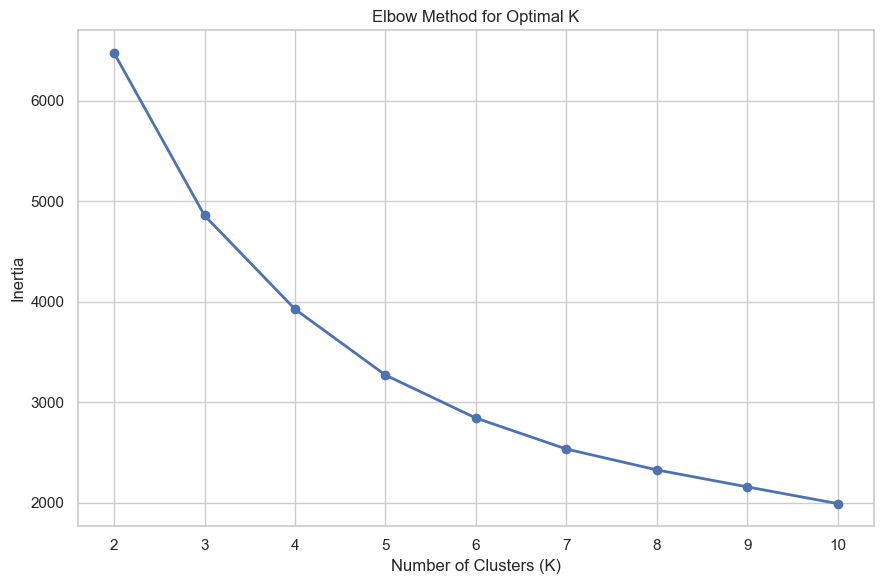

In [10]:
inertias = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(9, 6))
plt.plot(
    list(k_values),
    inertias,
    marker="o",
    linewidth=2
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

,K,Inertia,Silhouette Score
0,2,6476.507,0.433
1,3,4858.244,0.336
2,4,3925.426,0.333
3,5,3269.275,0.318
4,6,2841.417,0.313
5,7,2532.985,0.310
6,8,2325.075,0.302
7,9,2156.020,0.296
8,10,1989.405,0.277


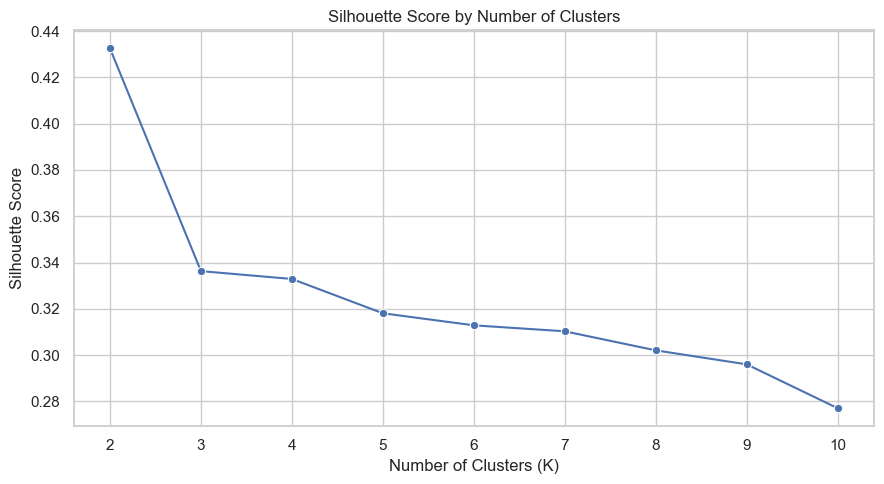

In [11]:
results = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette Score": silhouette_score(X_scaled, labels)
    })

model_results = pd.DataFrame(results)
display(model_results.round(3))

plt.figure(figsize=(9, 5))
sns.lineplot(
    data=model_results,
    x="K",
    y="Silhouette Score",
    marker="o"
)

plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(range(2, 11)))
plt.tight_layout()
plt.show()

In [12]:
best_k = 4  # Update based on the Elbow Method and silhouette results

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(X_scaled)

print("Selected number of clusters:", best_k)
print("\nCustomers in each cluster:")
print(rfm["Cluster"].value_counts().sort_index())

display(rfm.head())

Selected number of clusters: 4

Customers in each cluster:
Cluster
0     897
1    1174
2    1549
3     718
Name: count, dtype: int64


,CustomerID,Last_Purchase,Frequency,Monetary,Total_Units,Recency,Average_Purchase_Value,Historical_Customer_Value,Cluster
0,12346,2011-01-18 10:01:00,1,77183.60,74215,326,77183.600000,77183.60,1
1,12347,2011-12-07 15:52:00,7,4310.00,2458,3,615.714286,4310.00,3
2,12348,2011-09-25 13:13:00,4,1797.24,2341,76,449.310000,1797.24,1
3,12349,2011-11-21 09:51:00,1,1757.55,631,19,1757.550000,1757.55,0
4,12350,2011-02-02 16:01:00,1,334.40,197,311,334.400000,334.40,2


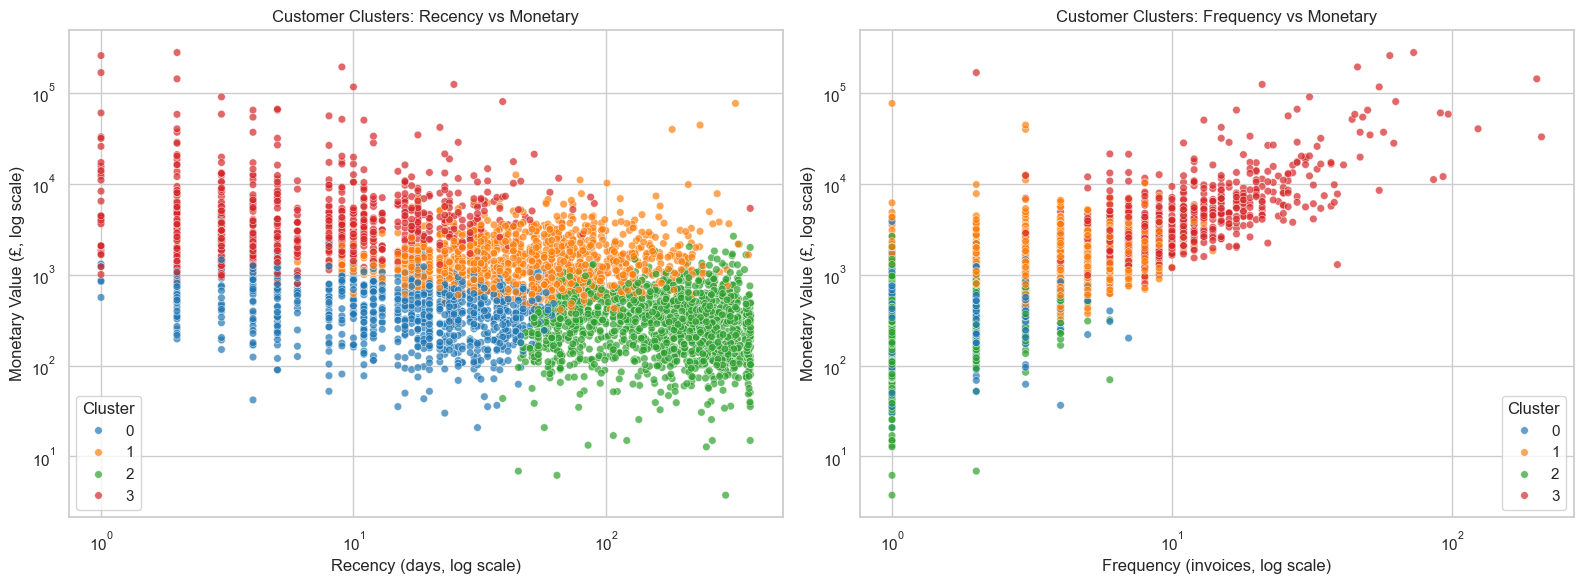

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Monetary",
    hue="Cluster",
    palette="tab10",
    alpha=0.7,
    s=30,
    ax=axes[0]
)

axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_title("Customer Clusters: Recency vs Monetary")
axes[0].set_xlabel("Recency (days, log scale)")
axes[0].set_ylabel("Monetary Value (£, log scale)")

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="tab10",
    alpha=0.7,
    s=30,
    ax=axes[1]
)

axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("Customer Clusters: Frequency vs Monetary")
axes[1].set_xlabel("Frequency (invoices, log scale)")
axes[1].set_ylabel("Monetary Value (£, log scale)")

plt.tight_layout()
plt.show()

In [14]:
cluster_profile = rfm.groupby("Cluster").agg(
    Customers=("CustomerID", "nunique"),
    Mean_Recency=("Recency", "mean"),
    Median_Recency=("Recency", "median"),
    Mean_Frequency=("Frequency", "mean"),
    Median_Frequency=("Frequency", "median"),
    Mean_Monetary=("Monetary", "mean"),
    Median_Monetary=("Monetary", "median"),
    Mean_Average_Purchase_Value=("Average_Purchase_Value", "mean"),
    Total_Revenue=("Monetary", "sum")
)

cluster_profile["Customer_Percentage"] = (
    cluster_profile["Customers"] / len(rfm) * 100
)

cluster_profile["Revenue_Percentage"] = (
    cluster_profile["Total_Revenue"] /
    cluster_profile["Total_Revenue"].sum() * 100
)

display(cluster_profile.round(2))

,Customers,Mean_Recency,Median_Recency,Mean_Frequency,Median_Frequency,Mean_Monetary,Median_Monetary,Mean_Average_Purchase_Value,Total_Revenue,Customer_Percentage,Revenue_Percentage
Cluster,,,,,,,,,,,
0,897,22.79,20.0,1.92,2.0,486.06,414.20,281.49,435999.12,20.68,4.91
1,1174,65.29,52.0,4.19,4.0,1822.98,1355.04,566.38,2140183.49,27.06,24.08
2,1549,192.27,187.0,1.35,1.0,360.55,303.16,290.76,558489.10,35.71,6.28
3,718,12.21,9.0,13.64,10.0,8011.89,3687.77,618.28,5752537.18,16.55,64.73


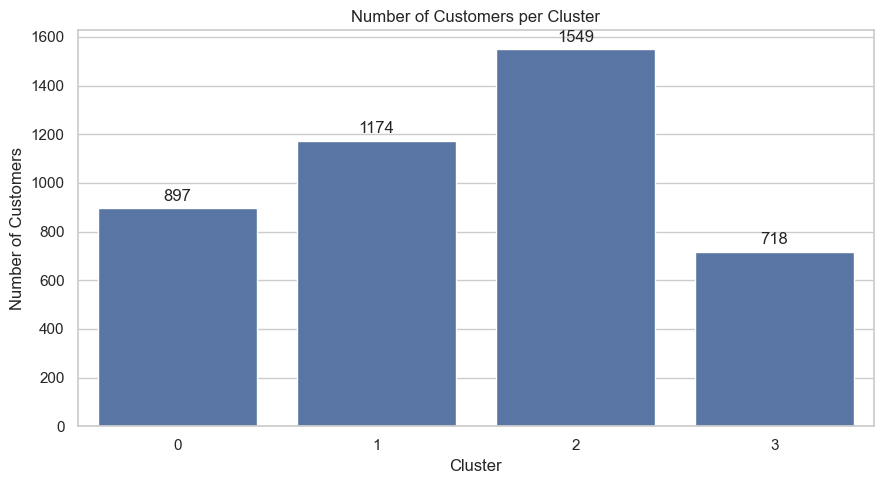

In [15]:
cluster_counts = rfm["Cluster"].value_counts().sort_index()

plt.figure(figsize=(9, 5))
ax = sns.barplot(
    x=cluster_counts.index.astype(str),
    y=cluster_counts.values
)

plt.title("Number of Customers per Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

In [16]:
profile = cluster_profile.copy()

# Rank cluster means from lowest to highest
profile["R_Rank"] = profile["Mean_Recency"].rank(
    ascending=True, method="dense"
)
profile["F_Rank"] = profile["Mean_Frequency"].rank(
    ascending=True, method="dense"
)
profile["M_Rank"] = profile["Mean_Monetary"].rank(
    ascending=True, method="dense"
)

def describe_segment(row):
    recent = row["R_Rank"] >= best_k - 1
    frequent = row["F_Rank"] >= best_k - 1
    high_spending = row["M_Rank"] >= best_k - 1

    if recent and frequent and high_spending:
        return "Loyal High-Value Customers"
    elif recent and high_spending:
        return "Recent High-Spending Customers"
    elif recent and frequent:
        return "Active Frequent Customers"
    elif row["R_Rank"] == 1 and not frequent:
        return "At-Risk / Inactive Customers"
    elif high_spending:
        return "High Historical Value Customers"
    else:
        return "Occasional / Developing Customers"

profile["Segment_Name"] = profile.apply(
    describe_segment, axis=1
)

display(
    profile[
        [
            "Customers",
            "Mean_Recency",
            "Mean_Frequency",
            "Mean_Monetary",
            "Customer_Percentage",
            "Revenue_Percentage",
            "Segment_Name"
        ]
    ].round(2)
)

,Customers,Mean_Recency,Mean_Frequency,Mean_Monetary,Customer_Percentage,Revenue_Percentage,Segment_Name
Cluster,,,,,,,
0,897,22.79,1.92,486.06,20.68,4.91,Occasional / Developing Customers
1,1174,65.29,4.19,1822.98,27.06,24.08,Loyal High-Value Customers
2,1549,192.27,1.35,360.55,35.71,6.28,Occasional / Developing Customers
3,718,12.21,13.64,8011.89,16.55,64.73,High Historical Value Customers


In [17]:
# Export customer-level RFM data with cluster labels
rfm.to_csv("customer_segments.csv", index=False)

# Export cluster-level summary
cluster_profile.to_csv("cluster_profiles.csv")

print("Export complete:")
print("1. customer_segments.csv")
print("2. cluster_profiles.csv")

Export complete:
1. customer_segments.csv
2. cluster_profiles.csv
